In [1]:
import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent))

import torch
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

np.random.seed(2025)

from ipywidgets import interact, FloatSlider, IntSlider
import matplotlib.patches as patches

from src.SHRED import SHRED, fit, predict
from src.processdata import TimeSeriesDataset, Padding
from src.utils import dim_reduction

## **Double gyre flow**

The double gyre flow is a time-dependent model for two counter-rotating vortices (gyres) in a rectangular domain. When time is introduced via a periodic perturbation, the central dividing line between the two gyres oscillates left and right, creating a time-varying velocity field that can lead to chaotic particle trajectories. The velocity field $\mathbf{v} = [u, v]^T$ in the domain $[0, L_x] \times [0, L_y]$ and in the time interval $[0, T]$ is given by

$$
\begin{align}
u(x, y, t) &= -\pi I \sin\left( \pi f(x, t) \right) \cos\left( \pi y \right)
\\
v(x, y, t) &= \pi I \cos\left( \pi f(x, t) \right) \sin\left( \pi y \right) \frac{\partial f}{\partial x}
\end{align}
$$

\
where $I$ is the intensity parameter, $f(x, t) = \epsilon \sin(\omega t) x^2 + (1 - 2\epsilon \sin(\omega t)) x $, $\epsilon$ and $\omega$ are the perturbation amplitude and the frequency of the oscillation, respectively.

## Solver

In [2]:
# DEFINE THE SYSTEM SOLVER

def double_gyre_flow(amplitude, frequency, x, y, t):
    '''
    Solve the double gyre flow problem

    Inputs
        amplitude                   (`float`)
        frequency                   (`float`)
        horizontal discretization   (`np.array[float]`, shape: (ny,))
        vertical discretization     (`np.array[float]`, shape: (nx,))
        time vector                 (`np.array[float]`, shape: (ntimes,))

    Output
        horizontal velocity matrix  (`np.array[float]`, shape: (ntimes, nx * ny)
        vertical velocity matrix    (`np.array[float]`, shape: (ntimes, nx * ny)
    '''

    xgrid, ygrid = np.meshgrid(x, y)         # spatial grid

    u = np.zeros((len(t), len(x), len(y)))   # horizontal velocity
    v = np.zeros((len(t), len(x), len(y)))   # vertical velocity

    intensity = 0.1   # intensity parameter

    f = lambda x,t: amplitude * np.sin(frequency * t) * x**2 + x - 2 * amplitude * np.sin(frequency * t) * x

    # compute solution
    for i in range(len(t)):
      u[i] = (-np.pi * intensity * np.sin(np.pi * f(xgrid, t[i])) * np.cos(np.pi * ygrid)).T
      v[i] = (np.pi * intensity * np.cos(np.pi * f(xgrid, t[i])) * np.sin(np.pi * ygrid) * (2 * amplitude * np.sin(frequency * t[i]) * xgrid + 1.0 - 2 * amplitude * np.sin(frequency * t[i]))).T

    return u, v

In [3]:
# SOLVE THE SYSTEM FOR A FIXED TRANSPORT TERM

amplitude = 0.25    # amplitude
frequency = 5.0     # frequency

# spatial discretization
nx = 50
ny = 25
Lx = 2.0
Ly = 1.0
x = np.linspace(0, Lx, nx)
y = np.linspace(0, Ly, ny)
nstate = len(x) * len(y)

# temporal discretization
dt = 0.1
T = 10.0
t = np.arange(0, T + dt, dt)
ntimes = len(t)

u, v = double_gyre_flow(amplitude, frequency, x, y, t)

In [4]:
# SOLUTION VISUALIZATION

def vorticity(u, v):
    dx = Lx / nx
    dy = Ly / ny
    du_dy = np.gradient(u, dy, axis = 1)
    dv_dx = np.gradient(v, dx, axis = 0)
    return dv_dx - du_dy

def plot_solution(time):

    which_time = (np.abs(t - time)).argmin()
    offset = 0.1

    plt.figure(figsize = (10,5))
    plt.contourf(x, y, vorticity(u[which_time], v[which_time]).T, cmap = 'seismic', levels = 100)
    plt.streamplot(x, y, u[which_time].T, v[which_time].T, color='black', linewidth = 1, density = 1)
    plt.axis('off')
    plt.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
    plt.title(f'Solution at time t = {round(time, 3)}')
    plt.grid(True)
    plt.gca().add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth = 5, edgecolor = 'black', facecolor = 'none'))


interact(plot_solution, time = FloatSlider(value = t[0], min = t[0], max = t[-1], step = (t[1]-t[0]), description='time', layout={'width': '400px', 'height': '50px'}));

interactive(children=(FloatSlider(value=0.0, description='time', layout=Layout(height='50px', width='400px'), …

In [5]:
# DATA GENERATION

amplitude_range = np.array([0.0, 0.5])
frequency_range = np.array([0.5, 2*np.pi])

# spatial discretization
nx = 50
ny = 25
Lx = 2.0
Ly = 1.0
x = np.linspace(0, Lx, nx)
y = np.linspace(0, Ly, ny)
nstate = len(x) * len(y)

# temporal discretization
dt = 0.1
T = 10.0
t = np.arange(0, T + dt, dt)
ntimes = len(t)

# training data generation
ntrajectories = 100
U = np.zeros((ntrajectories, ntimes, nx, ny))
V = np.zeros((ntrajectories, ntimes, nx, ny))

for i in range(ntrajectories):
  amplitude = (amplitude_range[1] - amplitude_range[0]) * np.random.rand() + amplitude_range[0]
  frequency = (frequency_range[1] - frequency_range[0]) * np.random.rand() + frequency_range[0]
  U[i], V[i] = double_gyre_flow(amplitude, frequency, x, y, t)

In [6]:
# DATA VISUALIZATION

def plot_data(which_trajectory, which_time):

    offset = 0.1

    plt.figure(figsize = (10,5))
    plt.contourf(x, y, vorticity(U[which_trajectory, which_time], V[which_trajectory, which_time]).T, cmap = 'seismic', levels = 100)
    plt.streamplot(x, y, U[which_trajectory, which_time].T, V[which_trajectory, which_time].T, color='black', linewidth = 1, density = 1)
    plt.axis('off')
    plt.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
    plt.title(f'Trajectory {which_trajectory} at time t = {round(t[which_time], 3)}')
    plt.grid(True)
    plt.gca().add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth = 5, edgecolor = 'black', facecolor = 'none'))

interact(plot_data, which_trajectory = IntSlider(min = 0, max = ntrajectories - 1, step = 1, description='Trajectory'), which_time = IntSlider(min = 0, max = ntimes - 1, step = 1, description='Time step'));

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), IntSlider(value=0, description='Ti…

## PreProcessing

In [7]:
# TORCH CONVERSION

U = torch.from_numpy(U.reshape(ntrajectories, ntimes, nstate))
V = torch.from_numpy(V.reshape(ntrajectories, ntimes, nstate))

In [8]:
# TRAIN-VALIDATION SPLITTING

split_ratio = 0.8

ntrain = round(split_ratio * ntrajectories)

idx_train = np.random.choice(ntrajectories, size = ntrain, replace = False)
mask = np.ones(ntrajectories)
mask[idx_train] = 0
idx_valid_test = np.arange(0, ntrajectories)[np.where(mask!=0)[0]]
idx_valid = idx_valid_test[::2]
idx_test = idx_valid_test[1::2]

nvalid = idx_valid.shape[0]
ntest = idx_test.shape[0]

Utrain = U[idx_train]
Uvalid = U[idx_valid]
Utest = U[idx_test]

Vtrain = V[idx_train]
Vvalid = V[idx_valid]
Vtest = V[idx_test]

## SHRED-ROM: pod based

In [9]:
POD_modes = 4

Residual energy is equal to  6.189785026138125e-07



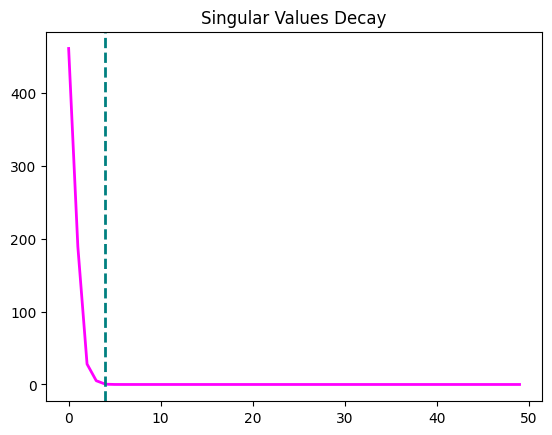

In [10]:
# DIMENSIONALITY REDUCTION - HORIZONTAL VELOCITY

Utrain, Uvalid, Utest, Utrain_proj, Uvalid_proj, Utest_proj, V1_POD = dim_reduction(Utrain, Uvalid, Utest, POD_modes)

Residual energy is equal to  5.280659835332175e-06



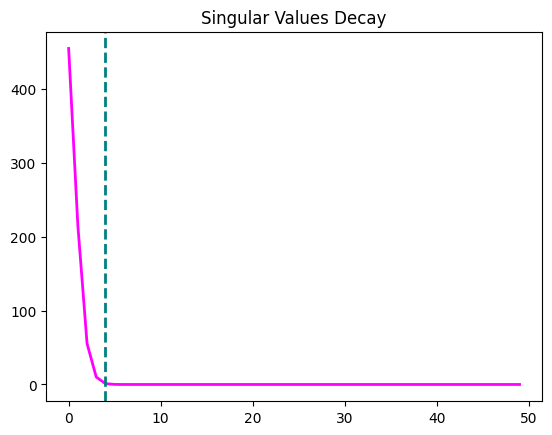

In [11]:
# DIMENSIONALITY REDUCTION - VERTICAL VELOCITY

Vtrain, Vvalid, Vtest, Vtrain_proj, Vvalid_proj, Vtest_proj, V2_POD = dim_reduction(Vtrain, Vvalid, Vtest, POD_modes)

In [12]:
# EXTRACT SENSORS DATA

nsensors = 3
idx_sensors = np.random.choice(nstate, size = nsensors, replace = False)

sensors_data_train = Utrain[:,:,idx_sensors]
sensors_data_valid = Uvalid[:,:,idx_sensors]
sensors_data_test = Utest[:,:,idx_sensors]

idx_sensors_x, idx_sensors_y = np.unravel_index(idx_sensors, (nx, ny))
sensors_coordinates = np.vstack((x[idx_sensors_x], y[idx_sensors_y]))

In [13]:
# BUILD TRAIN, VALIDATION AND TEST DATASETS WITH PADDING

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

lag = 25

train_data_in = Padding(sensors_data_train, lag).to(device)
valid_data_in = Padding(sensors_data_valid, lag).to(device)
test_data_in = Padding(sensors_data_test, lag).to(device)

train_data_out = Padding(torch.cat((Utrain_proj, Vtrain_proj), 2), 1).squeeze(1).to(device)
valid_data_out = Padding(torch.cat((Uvalid_proj, Vvalid_proj), 2), 1).squeeze(1).to(device)
test_data_out = Padding(torch.cat((Utest_proj, Vtest_proj), 2), 1).squeeze(1).to(device)

train_dataset = TimeSeriesDataset(train_data_in, train_data_out)
valid_dataset = TimeSeriesDataset(valid_data_in, valid_data_out)
test_dataset = TimeSeriesDataset(test_data_in, test_data_out)

print(f"Train dataset shape: \n{train_data_in.shape} -> {train_data_out.shape}")
print(f"Validation dataset shape: \n{valid_data_in.shape} -> {valid_data_out.shape}")
print(f"Test dataset shape: \n{test_data_in.shape} -> {test_data_out.shape}")

Using device: cpu
Train dataset shape: 
torch.Size([8080, 25, 3]) -> torch.Size([8080, 8])
Validation dataset shape: 
torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])
Test dataset shape: 
torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])


In [14]:
# SHRED TRAINING

shred = SHRED(nsensors, 2*POD_modes, hidden_size = 64, hidden_layers = 2, decoder_sizes = [], dropout = 0.1).to(device)
train_errors, valid_errors = fit(shred, train_dataset, valid_dataset, batch_size = 64, epochs = 200, lr = 1e-3, verbose = True, patience = 20)

Training:  73%|███████▎  | 146/200 [02:27<00:54,  1.01s/it, Train Error=0.55%, Val Error=0.59%, Patience=19]

Early stopping at epoch 147


In [15]:
shred.freeze()

UVtest_hat = shred(test_data_in).cpu().to(torch.float64)

Utest_hat = UVtest_hat[:,:POD_modes] @ V1_POD[:POD_modes, :]
Utest_hat = Utest_hat.reshape(ntest, ntimes, nx, ny)
Utest = Utest.reshape(ntest, ntimes, nx, ny)

Vtest_hat = UVtest_hat[:,POD_modes:] @ V2_POD[:POD_modes, :]
Vtest_hat = Vtest_hat.reshape(ntest, ntimes, nx, ny)
Vtest = Vtest.reshape(ntest, ntimes, nx, ny)

def plot_shred_reconstruction(which_test_trajectory, which_time):

    offset = 0.1

    plt.figure(figsize = (20,5))
    plt.subplot(1, 2, 1)
    plt.contourf(x, y, vorticity(Utest[which_test_trajectory, which_time],  Vtest[which_test_trajectory, which_time]).T, cmap = 'seismic', levels = 100)
    plt.streamplot(x, y, Utest[which_test_trajectory, which_time].T, Vtest[which_test_trajectory, which_time].T, color='black', linewidth = 1, density = 1)
    plt.axis('off')
    plt.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
    plt.title(f'Test case {which_test_trajectory} at time t = {round(t[which_time], 3)}')
    plt.grid(True)
    plt.gca().add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth = 5, edgecolor = 'black', facecolor = 'none'))
    for k in range(nsensors):
      plt.plot(sensors_coordinates[0, k], sensors_coordinates[1, k], 'o', mfc = 'magenta', mec = 'black', ms = 8, mew = 1.5)

    plt.subplot(1, 2, 2)
    plt.contourf(x, y, vorticity(Utest_hat[which_test_trajectory, which_time],  Vtest_hat[which_test_trajectory, which_time]).T, cmap = 'seismic', levels = 100)
    plt.streamplot(x, y, Utest_hat[which_test_trajectory, which_time].T, Vtest_hat[which_test_trajectory, which_time].T, color='black', linewidth = 1, density = 1)
    plt.axis('off')
    plt.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
    plt.title(f'SHRED reconstruction at time t = {round(t[which_time], 3)}')
    plt.grid(True)
    plt.gca().add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth = 5, edgecolor = 'black', facecolor = 'none'))
    for k in range(nsensors):
      plt.plot(sensors_coordinates[0, k], sensors_coordinates[1, k], 'o', mfc = 'magenta', mec = 'black', ms = 8, mew = 1.5)

interact(plot_shred_reconstruction, which_test_trajectory = IntSlider(value = 0, min = 0, max = ntest - 1, description='Test case'), which_time = IntSlider(min = 0, max = ntimes - 1, step = 1, description='Time step'));

interactive(children=(IntSlider(value=0, description='Test case', max=9), IntSlider(value=0, description='Time…